In [1]:
!pip install ultralytics roboflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 33.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 102.0 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [ultralytics]


In [2]:
import torch
print("GPU available:", torch.cuda.is_available())
print("GPU name:", torch.cuda.get_device_name(0))

GPU available: True
GPU name: Tesla T4


In [3]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="aApfpvy1QqmPolVadXBb")
project = rf.workspace("rubas-workspace-rvbwu").project("classmate-detection-9azjb")
version = project.version(1)
dataset = version.download("yolov8")


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Classmate-Detection-1 in yolov8:: 100%|██████████| 162/162 [00:00<00:00, 4519.57it/s]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [4]:
from ultralytics import YOLO

# Load a small pretrained model (good for small datasets)
model = YOLO("yolov8n.pt")

# Train
results = model.train(
    data=dataset.location + "/data.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    name="my_first_run"
)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Classmate-Detection-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=my_first_run, nbs=64, nms=None, opset=None, opti

In [5]:
from ultralytics import YOLO

model2 = YOLO("yolov8s.pt")   # bigger model than yolov8n

results2 = model2.train(
    data=dataset.location + "/data.yaml",
    epochs=80,        # trained for longer
    imgsz=640,
    batch=8,
    lr0=0.001,        # smaller learning rate
    patience=20,      # stops early if no improvement
    name="my_second_run"
)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Classmate-Detection-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=my_second_run, nbs=64, nms=None, opset=None, opt

In [6]:
metrics = model.val()

print("mAP@0.5:      ", metrics.box.map50)   # main accuracy score
print("mAP@0.5-0.95: ", metrics.box.map)
print("Precision:    ", metrics.box.mp)      # how many detections were correct
print("Recall:       ", metrics.box.mr)      # how many real objects were found

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,950 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 953.7±318.0 MB/s, size: 31.7 KB)
val: Scanning /content/Classmate-Detection-1/valid/labels.cache... 16 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 16/16 5.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 3.9it/s 0.3s
                   all         16         56      0.811      0.632      0.764       0.47
                   men          8         20       0.82        0.7      0.796      0.438
                 women         14         36      0.802      0.563      0.732      0.502
Speed: 0.4ms preprocess, 6.6ms inference, 0.0ms loss, 1.2ms postprocess per image
Results saved to /content/runs/detect/val
mAP@0.5:       0.7639676598228817
mAP@0.5-0.95:  0.4700366882528134
Precision:     0.8112388711

In [7]:
metrics_test = model.val(
    data=dataset.location + "/data.yaml",
    split="test"
)
print("Test mAP@0.5:   ", metrics_test.box.map50)
print("Test Precision: ", metrics_test.box.mp)
print("Test Recall:    ", metrics_test.box.mr)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,950 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1094.9±412.3 MB/s, size: 26.6 KB)
val: Scanning /content/Classmate-Detection-1/test/labels... 8 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 8/8 1.6Kit/s 0.0s
val: New cache created: /content/Classmate-Detection-1/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 8.0it/s 0.1s
                   all          8         31      0.695      0.586      0.715       0.44
                   men          6         12      0.634      0.435      0.571      0.345
                 women          7         19      0.755      0.737       0.86      0.535
Speed: 0.4ms preprocess, 6.6ms inference, 0.0ms loss, 1.5ms postprocess per image
Results saved to /content/runs/detect/val-2
Test mAP@0.5:    0.7154574301

['train_batch161.jpg', 'train_batch0.jpg', 'val_batch0_labels.jpg', 'train_batch2.jpg', 'BoxF1_curve.png', 'BoxR_curve.png', 'BoxPR_curve.png', 'train_batch1.jpg', 'train_batch162.jpg', 'val_batch0_pred.jpg', 'confusion_matrix_normalized.png', 'train_batch160.jpg', 'results.csv', 'weights', 'confusion_matrix.png', 'BoxP_curve.png', 'args.yaml', 'labels.jpg', 'results.png']


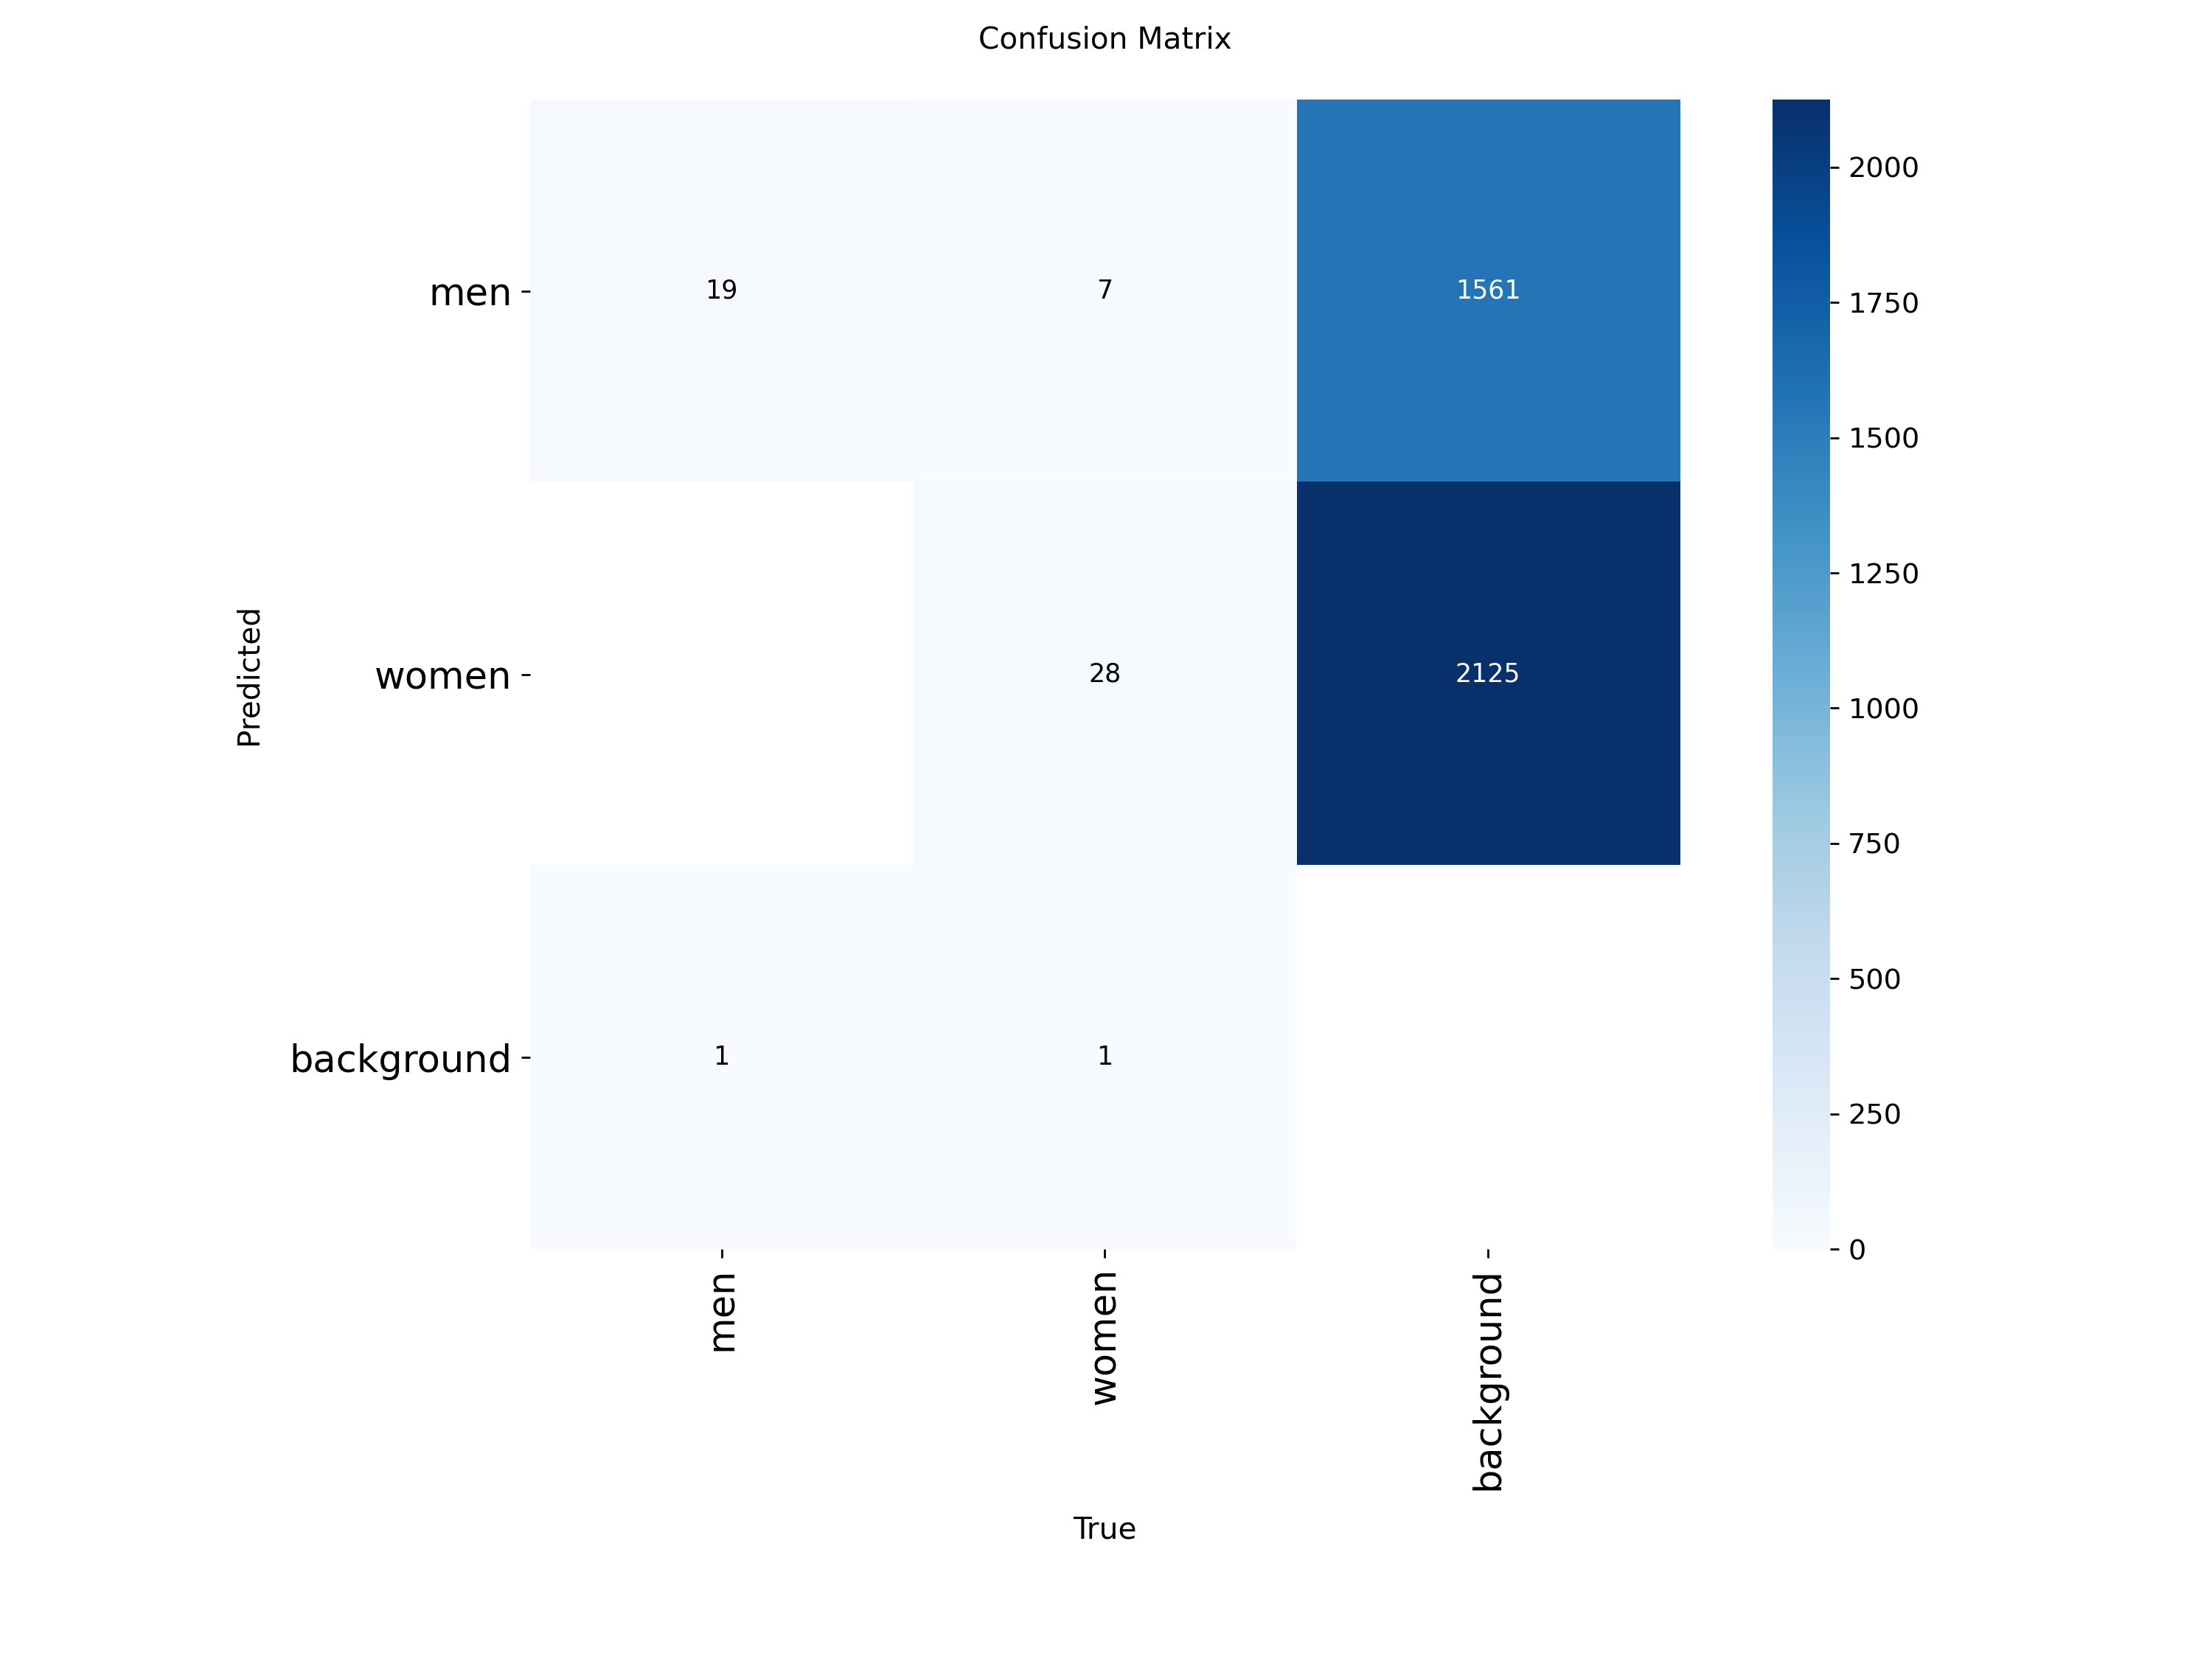

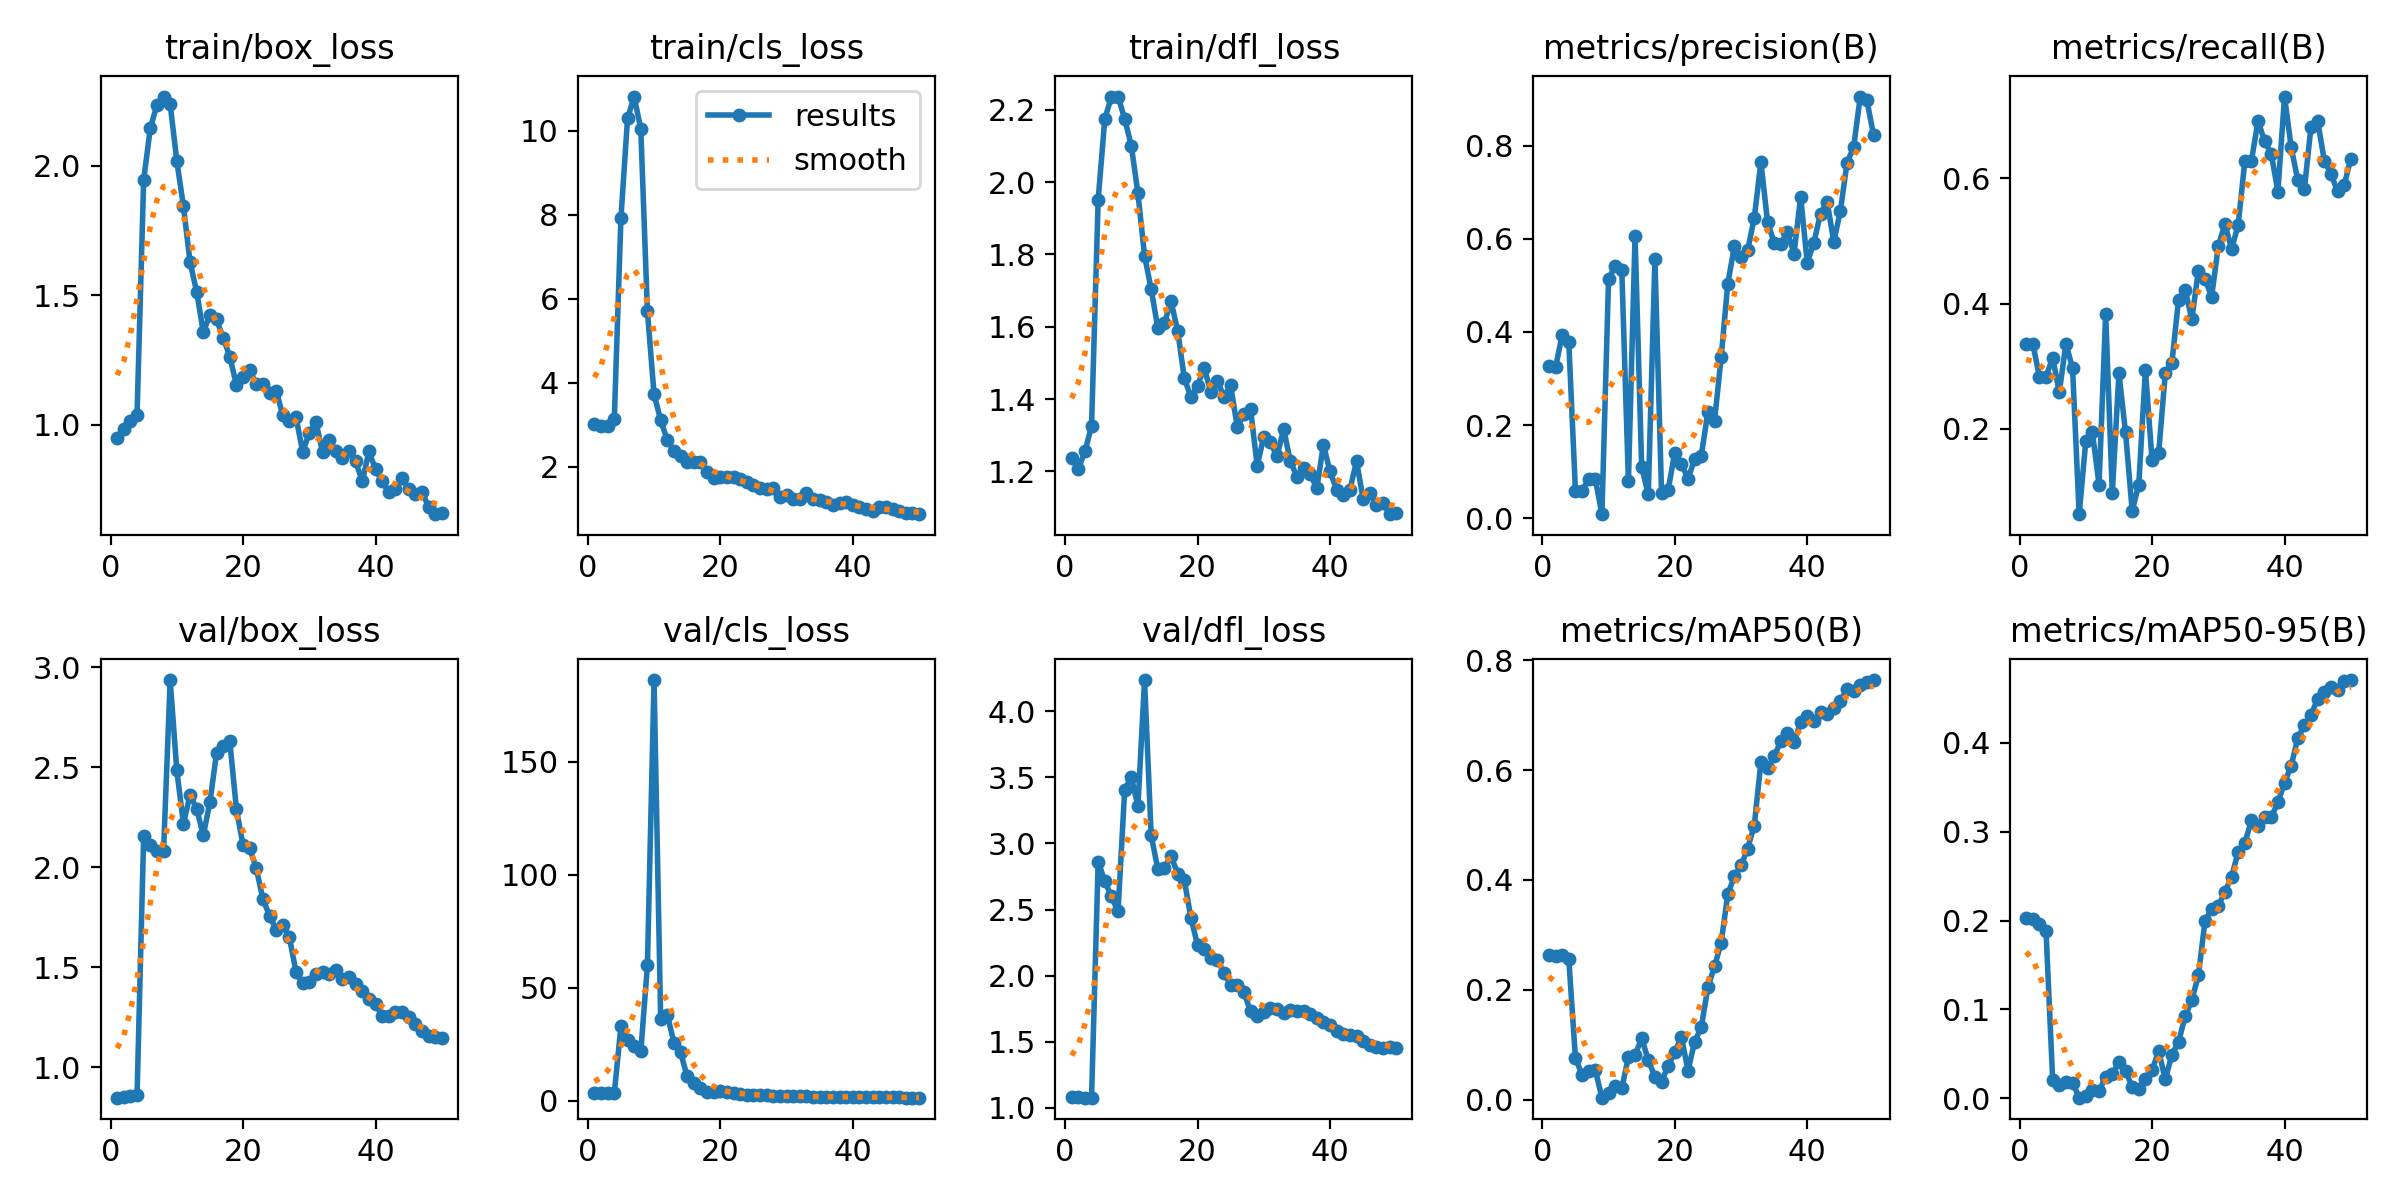

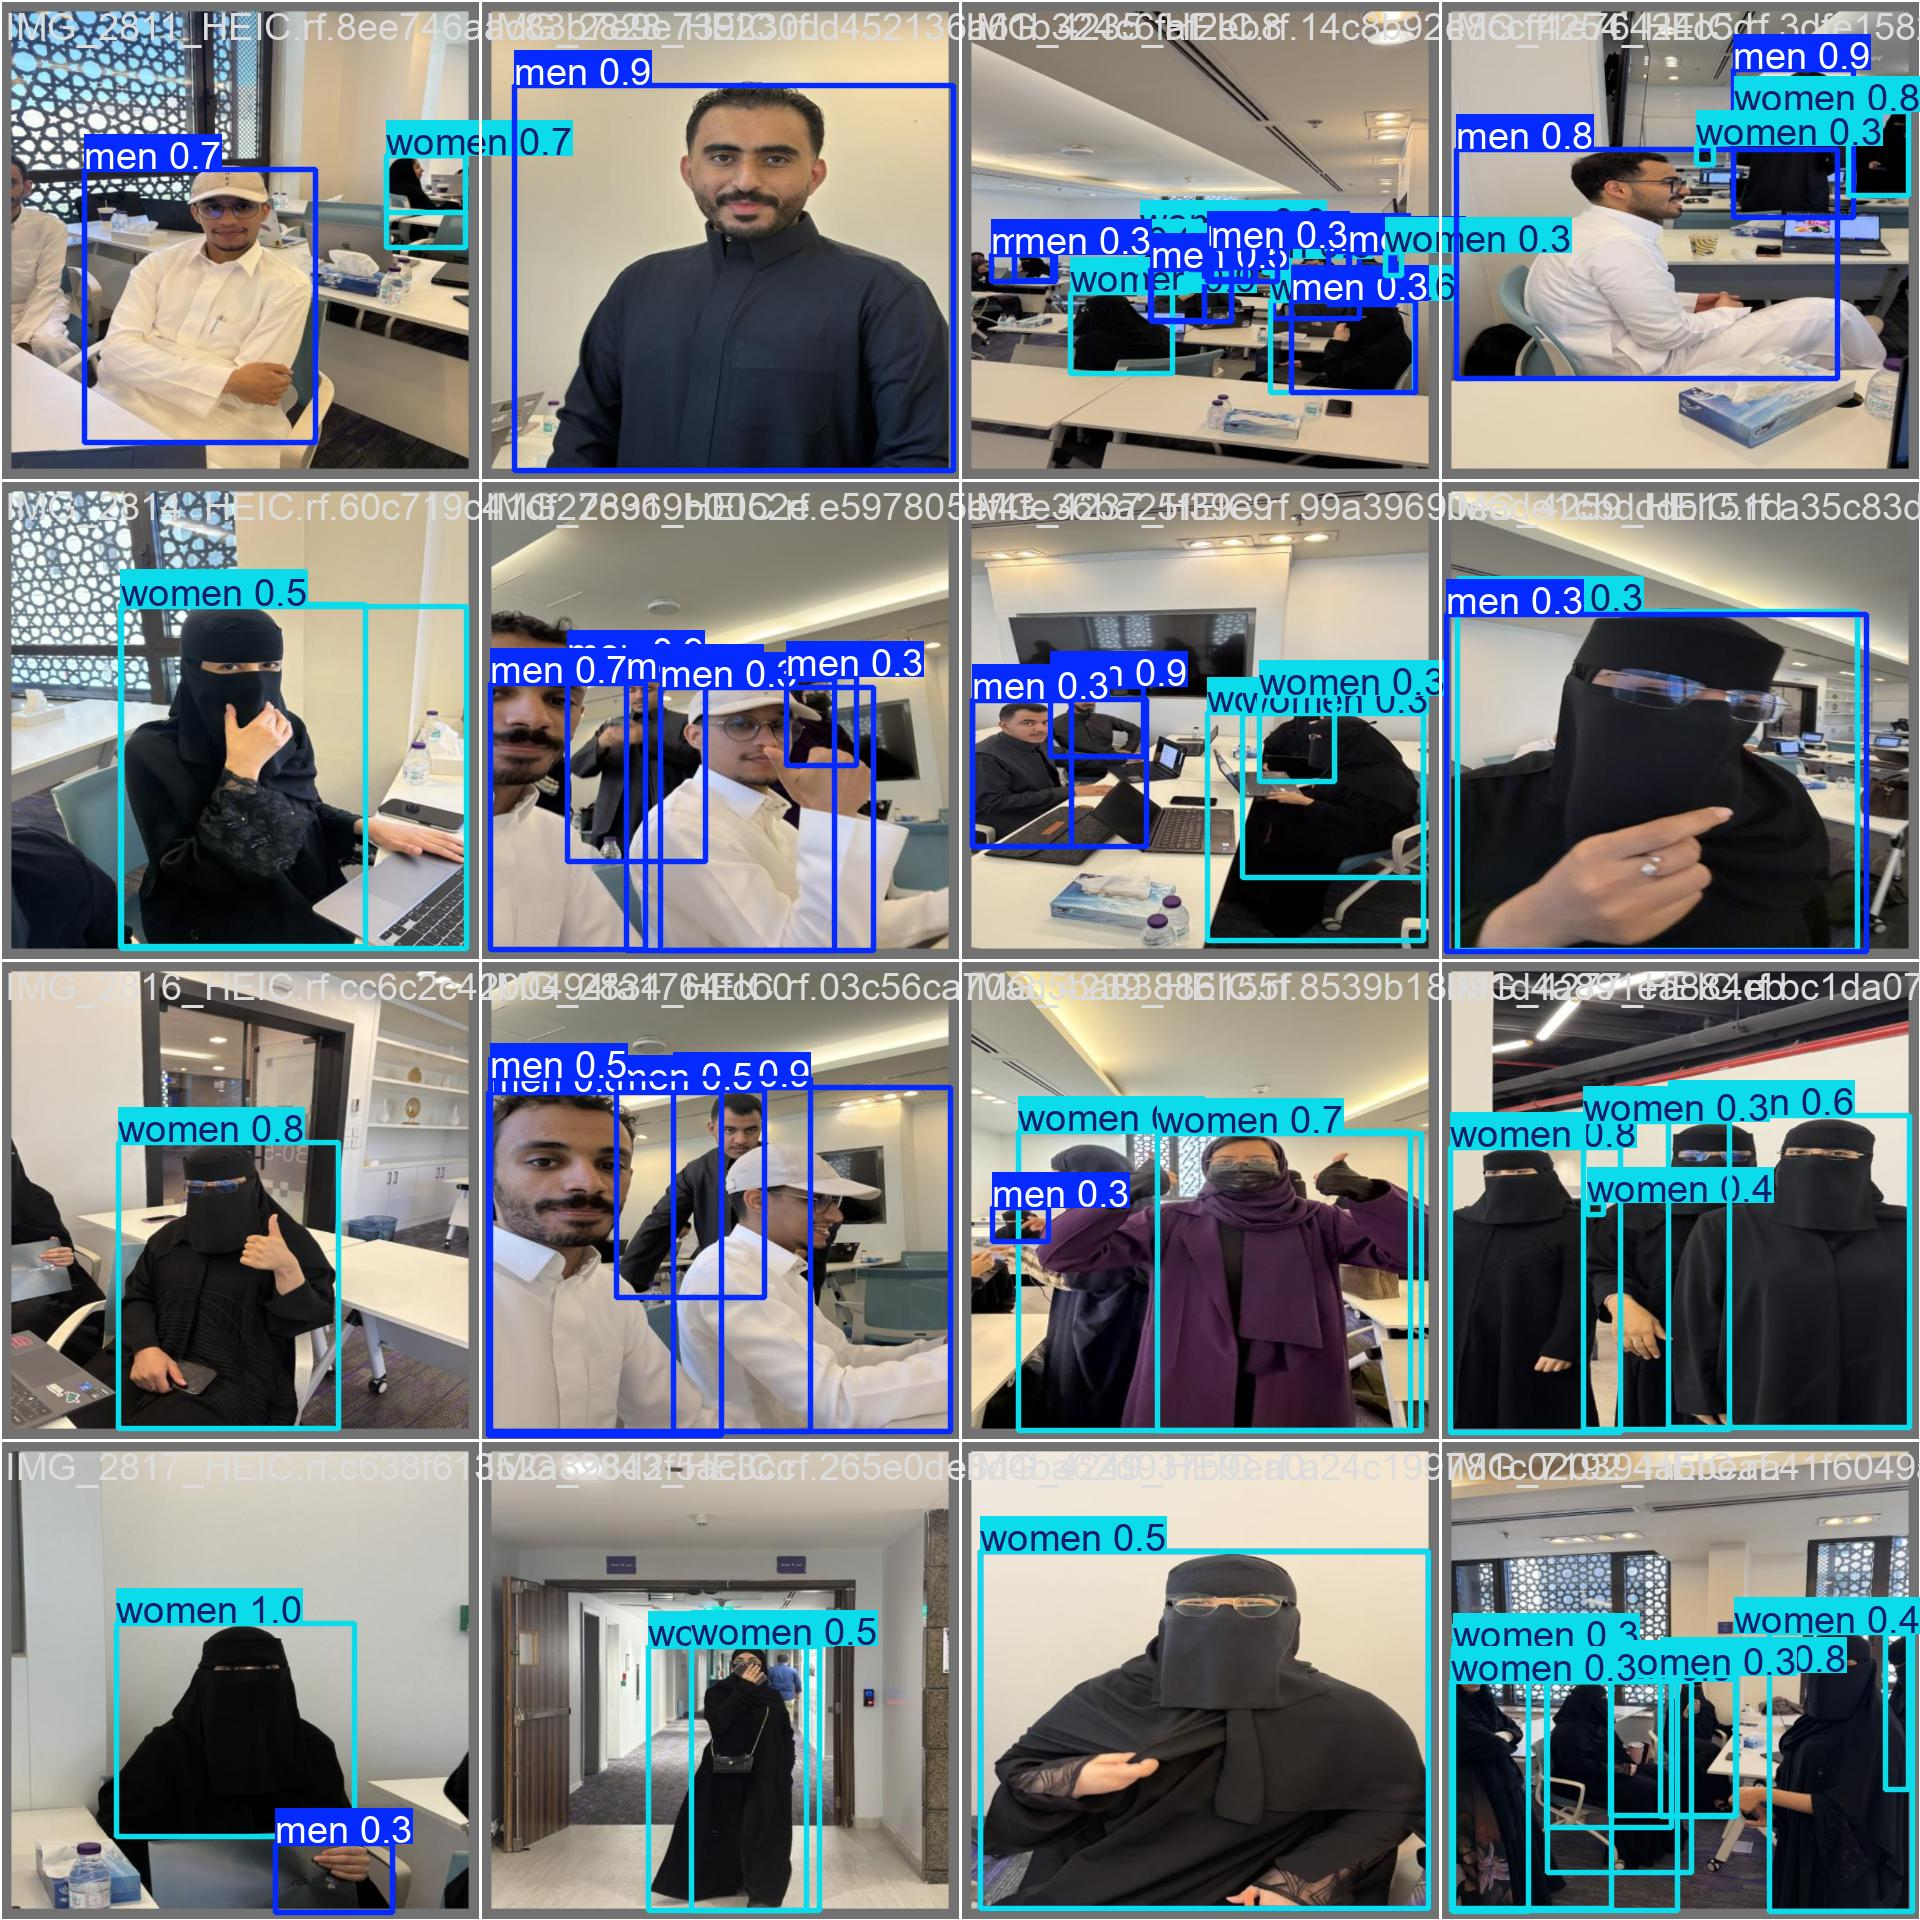

In [9]:
import os
from IPython.display import Image, display

run_path = "runs/detect/my_first_run/"

# See what files were actually saved
print(os.listdir(run_path))

# Always-present result images
display(Image(filename=run_path + "confusion_matrix.png"))
display(Image(filename=run_path + "results.png"))

# Show any validation prediction previews that exist (name/number can vary)
for f in sorted(os.listdir(run_path)):
    if f.startswith("val_batch") and f.endswith("_pred.jpg"):
        display(Image(filename=run_path + f))

In [10]:
pred = model.predict(
    source=dataset.location + "/test/images",
    save=True,
    conf=0.25      # lower this to catch more objects, raise it to reduce false boxes
)
print("Predicted images saved to:", pred[0].save_dir)


image 1/8 /content/Classmate-Detection-1/test/images/IMG_2813_HEIC.rf.d44e2b0884b50f73385ddbc5c0087e98.jpg: 640x640 1 women, 7.5ms
image 2/8 /content/Classmate-Detection-1/test/images/IMG_2823_HEIC.rf.ab6b90e1bca6c9841bf6ddc15d918bde.jpg: 640x640 2 mens, 1 women, 7.5ms
image 3/8 /content/Classmate-Detection-1/test/images/IMG_2830_HEIC.rf.ea3573a6a354cb3540da90fc4b2e5639.jpg: 640x640 1 men, 7.5ms
image 4/8 /content/Classmate-Detection-1/test/images/IMG_2839_HEIC.rf.74a8ecef1cbc42689dd85a348d6f8eb2.jpg: 640x640 7 womens, 7.6ms
image 5/8 /content/Classmate-Detection-1/test/images/IMG_4244_HEIC.rf.fe7fc170c9b2007d0e6a179a133da85a.jpg: 640x640 1 women, 7.5ms
image 6/8 /content/Classmate-Detection-1/test/images/IMG_4258_HEIC.rf.05dabf5f9610e9c4dfda52c54965bd04.jpg: 640x640 2 mens, 2 womens, 7.8ms
image 7/8 /content/Classmate-Detection-1/test/images/IMG_4260_HEIC.rf.114fe7044973affe617b27b489db9999.jpg: 640x640 4 womens, 7.5ms
image 8/8 /content/Classmate-Detection-1/test/images/IMG_4285_HEI

In [11]:
from google.colab import files
from ultralytics import YOLO
from IPython.display import Image, display

uploaded = files.upload()   # pick one image

for filename in uploaded.keys():
    result = model.predict(source=filename, save=True, conf=0.25)
    out_dir = result[0].save_dir
    display(Image(filename=out_dir + "/" + filename))

Saving IMG_2819.HEIC to IMG_2819.HEIC

requirements: Ultralytics requirement ['pi-heif'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 250ms
Prepared 1 package in 42ms
Installed 1 package in 2ms
 + pi-heif==1.4.0

requirements: AutoUpdate success ✅ 0.6s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

image 1/1 /content/IMG_2819.HEIC: 640x480 2 mens, 19.0ms
Speed: 2.7ms preprocess, 19.0ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 480)
Results saved to /content/runs/detect/predict


ValueError: Cannot embed the 'heic' image format